# Tumor Grade and Overall Survival by ER Status in METABRIC

This project explores two questions. How does tumor grade differ between estrogen receptor (ER)–positive and ER-negative breast tumors? How does estimated overall survival compare between the two groups?

I joined the METABRIC patient and tumor sample tables using patient IDs, then compared age at diagnosis and tumor grade by ER status. For the unadjusted survival comparison, I used Kaplan–Meier curves and a log-rank test on the 1,938 patients with known ER status and complete survival information.

**Data source:** [METABRIC on cBioPortal](https://www.cbioportal.org/study/summary?id=brca_metabric)

**Python packages:** `pandas`, `matplotlib`, `lifelines`

In [1]:
import pandas as pd
print(pd.__version__)

2.3.3


In [2]:
url = "https://media.githubusercontent.com/media/cBioPortal/datahub/master/public/brca_metabric/data_clinical_patient.txt"
patients = pd.read_csv(url, sep="\t", comment="#")
patients.head()

,PATIENT_ID,LYMPH_NODES_EXAMINED_POSITIVE,NPI,CELLULARITY,CHEMOTHERAPY,COHORT,ER_IHC,HER2_SNP6,HORMONE_THERAPY,INFERRED_MENOPAUSAL_STATE,...,OS_STATUS,CLAUDIN_SUBTYPE,THREEGENE,VITAL_STATUS,LATERALITY,RADIO_THERAPY,HISTOLOGICAL_SUBTYPE,BREAST_SURGERY,RFS_MONTHS,RFS_STATUS
0,MB-0000,10.0,6.044,NaN,NO,1.0,Positve,NEUTRAL,YES,Post,...,0:LIVING,claudin-low,ER-/HER2-,Living,Right,YES,Ductal/NST,MASTECTOMY,140.500000,0:Not Recurred
1,MB-0002,0.0,4.020,High,NO,1.0,Positve,NEUTRAL,YES,Pre,...,0:LIVING,LumA,ER+/HER2- High Prolif,Living,Right,YES,Ductal/NST,BREAST CONSERVING,84.633333,0:Not Recurred
2,MB-0005,1.0,4.030,High,YES,1.0,Positve,NEUTRAL,YES,Pre,...,1:DECEASED,LumB,NaN,Died of Disease,Right,NO,Ductal/NST,MASTECTOMY,153.300000,1:Recurred
3,MB-0006,3.0,4.050,Moderate,YES,1.0,Positve,NEUTRAL,YES,Pre,...,0:LIVING,LumB,NaN,Living,Right,YES,Mixed,MASTECTOMY,164.933333,0:Not Recurred
4,MB-0008,8.0,6.080,High,YES,1.0,Positve,NEUTRAL,YES,Post,...,1:DECEASED,LumB,ER+/HER2- High Prolif,Died of Disease,Right,YES,Mixed,MASTECTOMY,18.800000,1:Recurred


In [3]:
patients.columns.tolist()

['PATIENT_ID',
 'LYMPH_NODES_EXAMINED_POSITIVE',
 'NPI',
 'CELLULARITY',
 'CHEMOTHERAPY',
 'COHORT',
 'ER_IHC',
 'HER2_SNP6',
 'HORMONE_THERAPY',
 'INFERRED_MENOPAUSAL_STATE',
 'SEX',
 'INTCLUST',
 'AGE_AT_DIAGNOSIS',
 'OS_MONTHS',
 'OS_STATUS',
 'CLAUDIN_SUBTYPE',
 'THREEGENE',
 'VITAL_STATUS',
 'LATERALITY',
 'RADIO_THERAPY',
 'HISTOLOGICAL_SUBTYPE',
 'BREAST_SURGERY',
 'RFS_MONTHS',
 'RFS_STATUS']

In [4]:
patients.columns.tolist()

['PATIENT_ID',
 'LYMPH_NODES_EXAMINED_POSITIVE',
 'NPI',
 'CELLULARITY',
 'CHEMOTHERAPY',
 'COHORT',
 'ER_IHC',
 'HER2_SNP6',
 'HORMONE_THERAPY',
 'INFERRED_MENOPAUSAL_STATE',
 'SEX',
 'INTCLUST',
 'AGE_AT_DIAGNOSIS',
 'OS_MONTHS',
 'OS_STATUS',
 'CLAUDIN_SUBTYPE',
 'THREEGENE',
 'VITAL_STATUS',
 'LATERALITY',
 'RADIO_THERAPY',
 'HISTOLOGICAL_SUBTYPE',
 'BREAST_SURGERY',
 'RFS_MONTHS',
 'RFS_STATUS']

In [5]:
patients["ER_IHC"].value_counts(dropna=False)

ER_IHC
Positve     1817
Negative     609
NaN           83
Name: count, dtype: int64

In [6]:
patients.groupby("ER_IHC")["AGE_AT_DIAGNOSIS"].mean()

ER_IHC
Negative    53.509622
Positve     62.641139
Name: AGE_AT_DIAGNOSIS, dtype: float64

In [7]:
patients.groupby("ER_IHC")["AGE_AT_DIAGNOSIS"].count()

ER_IHC
Negative     609
Positve     1817
Name: AGE_AT_DIAGNOSIS, dtype: int64

In [8]:
patients.groupby("ER_IHC")["AGE_AT_DIAGNOSIS"].agg(["count", "mean"])

,count,mean
ER_IHC,,
Negative,609,53.509622
Positve,1817,62.641139


in the METABRIC dataset, the average age at diagnosis was around 62.6 for the "positive" group, and, it had 1817 records and the "negative" group had a lower average at diagnosis with 53.5, a difference of around 9.1 years.The 83 records with missing ER status couldn't be assigned to either group, which is why I excluded them.

In [9]:
patients["ER_STATUS"] = patients["ER_IHC"].replace({"Positve": "Positive"})

In [10]:
#value_counts(dropna=False)

In [11]:
patients["ER_STATUS"].value_counts(dropna=False)

ER_STATUS
Positive    1817
Negative     609
NaN           83
Name: count, dtype: int64

In [12]:
patients.columns.tolist()

['PATIENT_ID',
 'LYMPH_NODES_EXAMINED_POSITIVE',
 'NPI',
 'CELLULARITY',
 'CHEMOTHERAPY',
 'COHORT',
 'ER_IHC',
 'HER2_SNP6',
 'HORMONE_THERAPY',
 'INFERRED_MENOPAUSAL_STATE',
 'SEX',
 'INTCLUST',
 'AGE_AT_DIAGNOSIS',
 'OS_MONTHS',
 'OS_STATUS',
 'CLAUDIN_SUBTYPE',
 'THREEGENE',
 'VITAL_STATUS',
 'LATERALITY',
 'RADIO_THERAPY',
 'HISTOLOGICAL_SUBTYPE',
 'BREAST_SURGERY',
 'RFS_MONTHS',
 'RFS_STATUS',
 'ER_STATUS']

In [13]:
sample_url = "https://media.githubusercontent.com/media/cBioPortal/datahub/master/public/brca_metabric/data_clinical_sample.txt"
samples = pd.read_csv(sample_url, sep="\t", comment="#")
samples.columns.tolist()

['PATIENT_ID',
 'SAMPLE_ID',
 'CANCER_TYPE',
 'CANCER_TYPE_DETAILED',
 'ER_STATUS',
 'HER2_STATUS',
 'GRADE',
 'ONCOTREE_CODE',
 'PR_STATUS',
 'SAMPLE_TYPE',
 'TUMOR_SIZE',
 'TUMOR_STAGE',
 'TMB_NONSYNONYMOUS']

In [14]:
samples["PATIENT_ID"].value_counts().head()

PATIENT_ID
MB-0000    1
MB-6195    1
MB-6185    1
MB-6187    1
MB-6188    1
Name: count, dtype: int64

In [15]:
print("Sample IDs missing:", samples["PATIENT_ID"].isna().sum())
print("Patient IDs missing:", patients["PATIENT_ID"].isna().sum())
print("Patient IDs unique:", patients["PATIENT_ID"].is_unique)

Sample IDs missing: 0
Patient IDs missing: 0
Patient IDs unique: True


In [16]:
patient_grades = patients.merge(
    samples[["PATIENT_ID", "GRADE"]],
    on="PATIENT_ID",
    how="left",
    validate="one_to_one",
    indicator=True,
)

In [17]:
patient_grades["_merge"].value_counts()

_merge
both          2509
left_only        0
right_only       0
Name: count, dtype: int64

In [18]:
patient_grades["GRADE"].value_counts(dropna=False)

GRADE
3.0    1198
2.0     976
1.0     214
NaN     121
Name: count, dtype: int64

In [19]:
pd.crosstab(patient_grades["ER_STATUS"], patient_grades["GRADE"])

GRADE,1.0,2.0,3.0
ER_STATUS,,,
Negative,14,80,499
Positive,197,865,681


In [20]:
pd.crosstab(
    patient_grades["ER_STATUS"],
    patient_grades["GRADE"],
    normalize="index",
) * 100

GRADE,1.0,2.0,3.0
ER_STATUS,,,
Negative,2.360877,13.490725,84.148398
Positive,11.302352,49.627080,39.070568


Among METABRIC records with both ER status and tumor grade recorded, 84.15% of ER-negative tumors were grade 3, compared with 39.07% of ER-positive tumors. The ER-negative group had a higher proportion of grade 3 tumors by 45.08 percent. 

In [21]:
grade_percentages = pd.crosstab(
    patient_grades["ER_STATUS"],
    patient_grades["GRADE"],
    normalize="index",
) * 100

grade_percentages.round(2)

GRADE,1.0,2.0,3.0
ER_STATUS,,,
Negative,2.36,13.49,84.15
Positive,11.30,49.63,39.07


(0.0, 100.0)

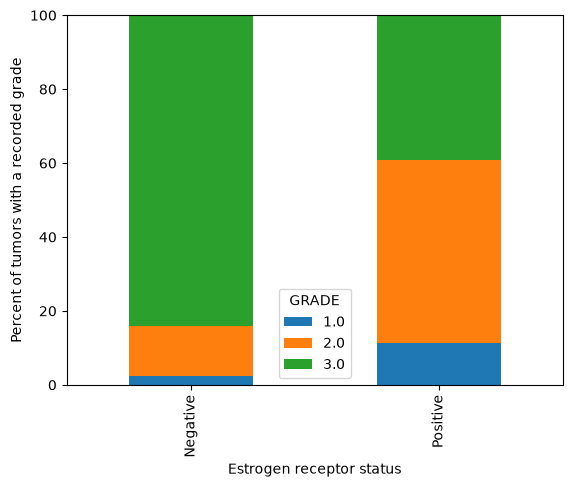

In [22]:
ax = grade_percentages.plot(kind="bar", stacked=True)
ax.set_xlabel("Estrogen receptor status")
ax.set_ylabel("Percent of tumors with a recorded grade")
ax.set_ylim(0, 100)

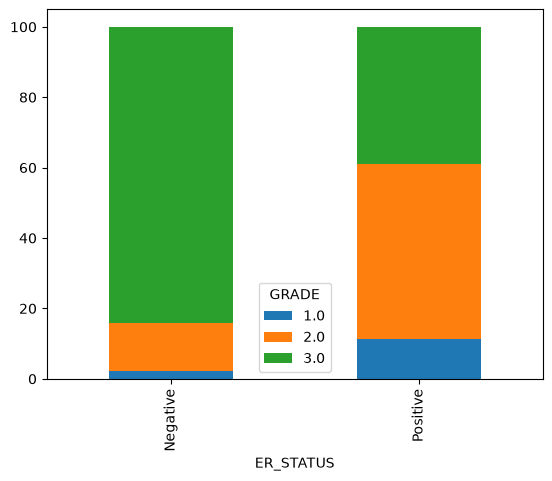

In [23]:
ax = grade_percentages.plot(kind="bar", stacked=True)


In [24]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


(0.0, 100.0)

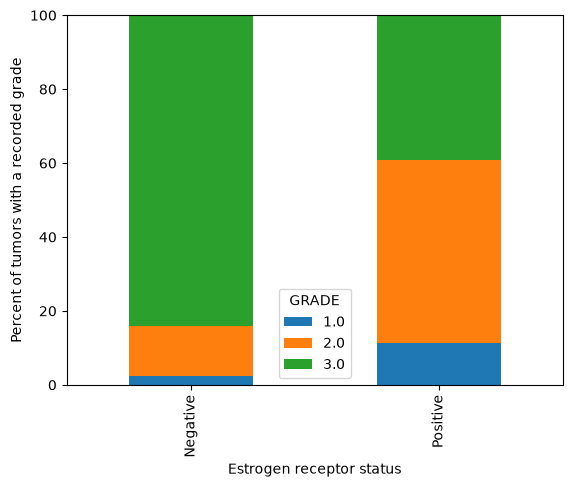

In [25]:
ax = grade_percentages.plot(kind="bar", stacked=True)
ax.set_xlabel("Estrogen receptor status")
ax.set_ylabel("Percent of tumors with a recorded grade")
ax.set_ylim(0, 100)

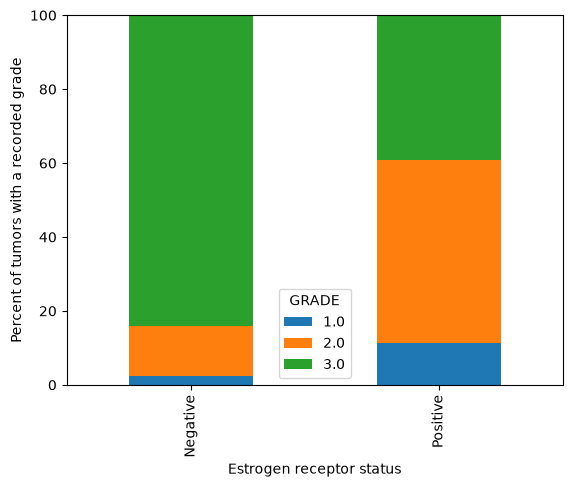

In [26]:
import matplotlib.pyplot as plt

ax = grade_percentages.plot(kind="bar", stacked=True)
ax.set_xlabel("Estrogen receptor status")
ax.set_ylabel("Percent of tumors with a recorded grade")
ax.set_ylim(0, 100)
plt.show()

In [27]:
patients["OS_STATUS"].value_counts(dropna=False)

OS_STATUS
1:DECEASED    1144
0:LIVING       837
NaN            528
Name: count, dtype: int64

In [28]:
patients["OS_MONTHS"].isna().sum()

np.int64(528)

In [29]:
missing_time = patients["OS_MONTHS"].isna()
missing_status = patients["OS_STATUS"].isna()

(missing_time != missing_status).sum()

np.int64(0)

In [30]:
survival_records = patients[~missing_time]
survival_records["ER_STATUS"].value_counts(dropna=False)

ER_STATUS
Positive    1499
Negative     439
NaN           43
Name: count, dtype: int64

In [31]:
survival_groups = survival_records.dropna(subset=["ER_STATUS"]).copy()

survival_groups["EVENT_OBSERVED"] = survival_groups["OS_STATUS"].map({
    "1:DECEASED": 1,
    "0:LIVING": 0,
})

survival_groups["EVENT_OBSERVED"].value_counts(dropna=False)

EVENT_OBSERVED
1    1126
0     812
Name: count, dtype: int64

In [32]:
survival_groups["OS_MONTHS"].describe()

count    1938.000000
mean      125.149518
std        76.138510
min         0.100000
25%        60.675000
50%       115.816667
75%       185.100000
max       355.200000
Name: OS_MONTHS, dtype: float64

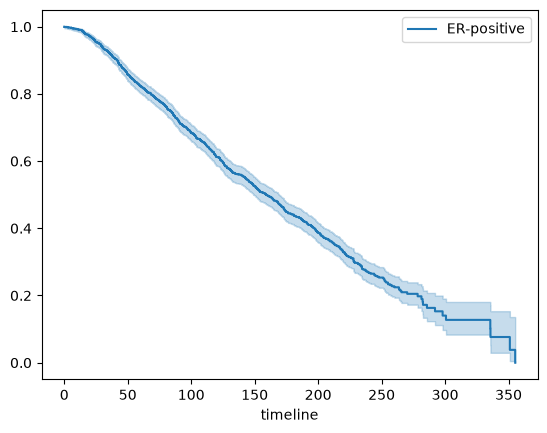

In [33]:
from lifelines import KaplanMeierFitter

er_positive = survival_groups[survival_groups["ER_STATUS"] == "Positive"]

km = KaplanMeierFitter()
km.fit(
    durations=er_positive["OS_MONTHS"],
    event_observed=er_positive["EVENT_OBSERVED"],
    label="ER-positive",
)
km.plot_survival_function()
plt.show()

In [34]:
%pip install lifelines


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


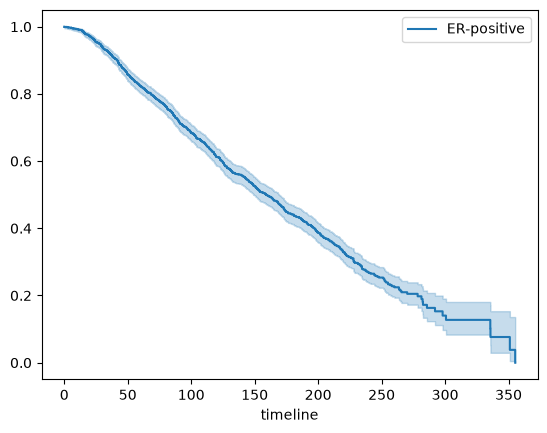

In [35]:
from lifelines import KaplanMeierFitter

er_positive = survival_groups[survival_groups["ER_STATUS"] == "Positive"]

km = KaplanMeierFitter()
km.fit(
    durations=er_positive["OS_MONTHS"],
    event_observed=er_positive["EVENT_OBSERVED"],
    label="ER-positive",
)
km.plot_survival_function()
plt.show()

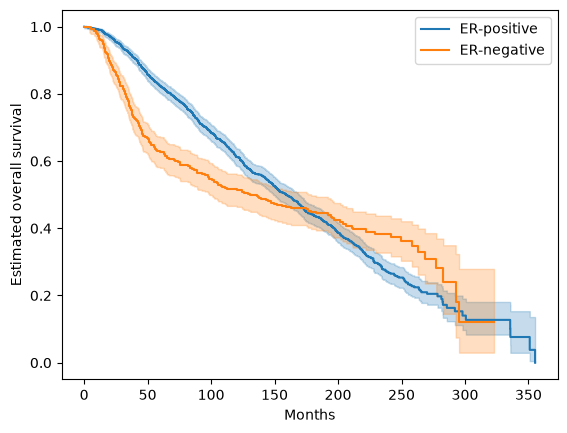

In [36]:
er_negative = survival_groups[survival_groups["ER_STATUS"] == "Negative"]

km_negative = KaplanMeierFitter()
km_negative.fit(
    durations=er_negative["OS_MONTHS"],
    event_observed=er_negative["EVENT_OBSERVED"],
    label="ER-negative",
)

ax = km.plot_survival_function()
km_negative.plot_survival_function(ax=ax)
ax.set_xlabel("Months")
ax.set_ylabel("Estimated overall survival")
plt.show()

In [37]:
print(f"ER-positive: {km.predict(60):.1%}")
print(f"ER-negative: {km_negative.predict(60):.1%}")

ER-positive: 82.3%
ER-negative: 62.8%


In the METABRIC cohort that I analyzed, the estimated five-year overall survival was 82.3% for ER-positive patients and 62.8% for ER-negative patients. This shows a difference of 19.5%. These Kaplan-Meier estimates are unadjusted, so differences in age at diagnosis, tumor grade, or other factors may contribute to the gap.

In [38]:
from lifelines.statistics import logrank_test

result = logrank_test(
    er_positive["OS_MONTHS"],
    er_negative["OS_MONTHS"],
    event_observed_A=er_positive["EVENT_OBSERVED"],
    event_observed_B=er_negative["EVENT_OBSERVED"],
)

print(f"Test statistic: {result.test_statistic:.2f}")
print(f"P-value: {result.p_value:.3g}")

Test statistic: 2.55
P-value: 0.11


In this METABRIC analysis, the estimated 5-year overall survival was 82.3% in ER-positive patients and 62.8% in ER-negative patients, a 19.5% difference. The unadjusted log-rank test was not statistically significant across follow-up (χ²(1) = 2.55, p = 0.11).